<a href="https://colab.research.google.com/github/w4bo/AA2627-unibo-dcai/blob/main/slides/lab-01-augmentation.ipynb" target="_parent"><img src="img/colab-badge.svg" alt="Open In Colab"/></a>

---
title: "Data Augmentation"
---

# Learning outcomes

By the end of this notebook, you should be able to:

- Build `sklearn` pipelines and optimize their hyper-parameters.
- Explain class imbalance and why accuracy can be misleading.
- Distinguish data augmentation from resampling.
- Compare random oversampling, undersampling, SMOTE, ADASYN, and class weighting.
- Place resampling correctly inside a cross-validation pipeline.
- Select appropriate metrics and decision thresholds.


# 0. The estimator interface

An **estimator** is a scikit-learn object that learns from data.

Most estimators follow the same pattern:

```python
model = Estimator(parameters)
model.fit(X_train, y_train)
predictions = model.predict(X_test)
```

This shared API is one reason scikit-learn is pleasant to use.

# 1. Why pipelines matter

A machine-learning pipeline is rarely just a classifier. 

- A real workflow often includes missing-value handling, scaling, categorical encoding, feature selection, resampling, and then the final estimator.
- `sklearn.pipeline.Pipeline` packages these steps into one object with a single `fit`, `predict`, and `predict_proba` interface.
    - This matters because *every preprocessing step must be learned only from the training data*.
    - A pipeline makes that discipline automatic during train/test splits and cross-validation.


# 2. A basic sklearn pipeline

```python
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000)),
])

pipeline.fit(X_train, y_train)
pipeline.predict(X_test)
```

A typical pipeline chains transformers and a final estimator:

- The important point is that `StandardScaler` is fitted on `X_train` only.
- The test set is transformed using the training-set scaling parameters.


# 3. Pipelines expose hyper-parameters

Pipeline parameters are addressed with the pattern:

```text
step_name__parameter_name
```

For example, if the classifier step is named `classifier`, then the logistic-regression regularization strength is `classifier__C`.

```python
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000)),
])

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"],
}
```

This lets us tune preprocessing choices and model choices together, while keeping the evaluation leakage-safe.


# 4. Hyper-parameter optimization with cross-validation

`GridSearchCV` trains and evaluates many pipeline configurations using cross-validation.

- Each fold fits preprocessing and the classifier only on the training part of that fold.
- The scoring function should match the task.

```python
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = GridSearchCV( # alternative to GridSeach?
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1", # why?
    cv=cv,
)

search.fit(X_train, y_train)
search.best_params_
```


# 5. The imbalanced classification problem

Many important binary classification problems have one class that is much rarer than the other.

<details>
<summary>Examples</summary>
Fraud detection, medical diagnosis, safety incidents, customer churn, credit default, and equipment failures.
</details>

We call the frequent class the **majority class** and the rare class the **minority class**.

- Usually, the minority class is the positive class: `1`.

When classes are imbalanced, **accuracy can be misleading**. *Why?*

<details>
<summary>Answer</summary>
If only 5% of customers churn, a classifier that always predicts "no churn" reaches 95% accuracy while finding no churners at all.
</details>

Useful metrics include:

- **Precision**: among predicted positives, how many were actually positive?
- **Recall** or sensitivity: among actual positives, how many did we find?
- **Specificity**: among actual negatives, how many did we correctly reject?
- **F1 score**: harmonic mean of precision and recall.

# 6. Methods for handling imbalance

Common strategies include:

- **No treatment**: train directly and evaluate carefully.
- **Class weights**: make minority-class errors more expensive.
- **Undersampling**: remove majority examples.
- **Oversampling**: duplicate minority examples.
- **SMOTE and variants**: synthesize minority examples.

# Data augmentation versus SMOTE

*Data augmentation* applies domain-specific label-preserving transformations: image rotations, sensor noise, audio crops, or text perturbations.

*SMOTE* creates tabular rows by interpolation in feature space.

- The important question is whether the generated record could exist in the real data-generating process.


# 7. How SMOTE works

SMOTE creates new minority-class observations instead of duplicating existing ones [@chawla2002smote].

For a minority point $x_i$, it selects a nearby minority point $x_j$ and creates: $x_{new} = x_i + \lambda * (x_j - x_i)$

- The intuition is simple: fill sparse minority regions. 
- The risk is also simple: interpolation may create impossible records.


# Other algorithms

**Borderline-SMOTE** focuses on minority observations near the class boundary [@han2005borderline].

- These are the points a classifier is most likely to confuse with the majority class.
- This can help boundary recall, but noisy or mislabeled boundary points can be reinforced.

**SMOTE-NC** handles mixed numerical and categorical data [@chawla2002smote].

- Numerical columns are interpolated.
- Categorical columns are chosen from neighboring minority examples.

**ADASYN** estimates local difficulty from nearest neighbors [@he2008adasyn].

- The method shifts attention toward hard minority regions, which can be useful or risky depending on label noise and class overlap.
- Minority observations surrounded by many majority observations receive larger sampling weights.
- Creates more synthetic minority examples around locally difficult observations.
    - This can improve recall in hard regions, but it can also amplify mislabeled points.


# 8. Leakage warning

Resampling *is part of model training*: it must be learned from the training data only.

- Do **not** apply SMOTE or oversampling before splitting the data. 
    - If synthetic points are created before a train/test split, information from validation or test observations can leak into the training set through nearest-neighbor interpolation or duplicated examples.
- The same rule applies to cross-validation: resampling must happen **inside each training fold**, not once globally before cross-validation.
- This is why we use `imblearn.pipeline.Pipeline` whenever the pipeline contains a sampler.


# 9. Install imbalanced-learn

```bash
pip install imbalanced-learn
```


# 10. Pipelines with resampling need imblearn

`sklearn.pipeline.Pipeline` is designed for transformers and estimators.

- Resamplers such as SMOTE change both `X` and `y`, so they need `imblearn.pipeline.Pipeline`.
- Resampling is part of training, so it must happen inside the pipeline and inside each cross-validation fold.

```python
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

pipeline = ImbPipeline([
    ("preprocessing", preprocessor),
    ("sampler", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(max_iter=2000)),
])
```

Sklearn estimator implements a fit method to learn from data:

- `estimator = obj.fit(data, targets)`

Resampler: to resample a data sets, each sampler implements a fit_resample method:

- `data_resampled, targets_resampled = obj.fit_resample(data, targets)`


In [1]:
#| echo: false
# Install the sampler library only when the runtime does not already provide it.
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("imblearn") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
#| echo: false
# Keep one seed so every plot and cross-validation split is reproducible in class.
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    accuracy_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import ADASYN, BorderlineSMOTE, RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
plt.style.use("seaborn-v0_8-whitegrid")


# 11. Create a deliberately imbalanced dataset

We will use a synthetic binary classification dataset so the notebook is reproducible without external data downloads.

- `y=1` is a rare high-risk event, such as fraud, churn, default, or failure.


In [3]:
#| echo: false
# Build a controlled rare-event problem with about 6% positive examples.
X_array, y_array = make_classification(
    n_samples=5000,
    n_features=12,
    n_informative=5,
    n_redundant=3,
    n_clusters_per_class=2,
    weights=[0.94, 0.06],
    class_sep=0.9,
    flip_y=0.02,
    random_state=RANDOM_STATE,
)

feature_names = [f"feature_{i:02d}" for i in range(X_array.shape[1])]
X = pd.DataFrame(X_array, columns=feature_names)
y = pd.Series(y_array, name="high_risk")

class_counts = y.value_counts().sort_index()
class_rates = y.value_counts(normalize=True).sort_index()

pd.DataFrame({"count": class_counts, "rate": class_rates.round(3)})


,count,rate
high_risk,,
0,4658,0.932
1,342,0.068


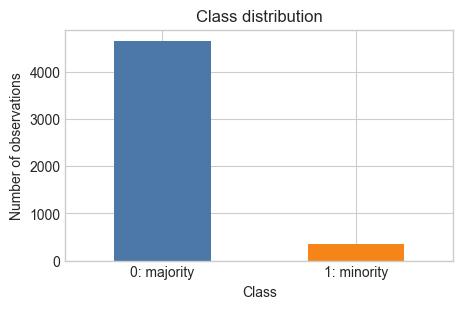

In [4]:
#| echo: false
# Visualize the base rate before discussing any model metrics.
fig, ax = plt.subplots(figsize=(5, 3))
class_counts.plot(kind="bar", ax=ax, color=["#4C78A8", "#F58518"])
ax.set_title("Class distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of observations")
ax.set_xticklabels(["0: majority", "1: minority"], rotation=0)
plt.show()


# 12. Why accuracy fails?


# Majority-class baseline

A classifier that always predicts the majority class can look strong by accuracy alone. But it has zero recall for the minority class.

In [5]:
#| echo: false
# Predicting only the majority class gives high accuracy but no minority recall.
always_majority = np.zeros_like(y)

accuracy = (always_majority == y).mean()
precision = precision_score(y, always_majority, zero_division=0)
recall = recall_score(y, always_majority, zero_division=0)
f1 = f1_score(y, always_majority, zero_division=0)

pd.DataFrame(
    [{"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}]
).round(3)


,accuracy,precision,recall,f1
0,0.932,0.0,0.0,0.0


# 13. Visual intuition

Before full pipelines, inspect resampling on a small 2D dataset.

The goal is not the best model. The goal is to see how the training set changes.


- *Undersampling* removes majority rows.
- *Oversampling* duplicates minority rows.
- *SMOTE* interpolates between minority neighbors.
- *Borderline-SMOTE* focuses near the class boundary.
- *ADASYN* focuses on locally difficult minority regions.

# Visual intuition

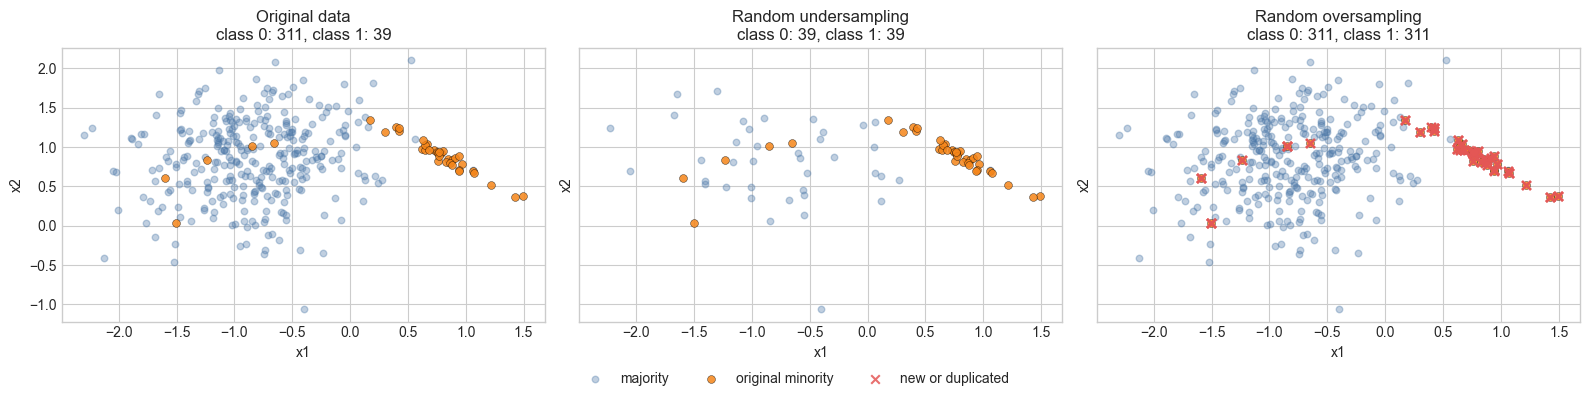

In [6]:
#| echo: false

# Create a small two-feature dataset so synthetic samples can be plotted directly.
X_2d_array, y_2d_array = make_classification(
    n_samples=350,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.9, 0.1],
    class_sep=0.85,
    flip_y=0.03,
    random_state=RANDOM_STATE,
)

X_2d = pd.DataFrame(X_2d_array, columns=["x1", "x2"])
y_2d = pd.Series(y_2d_array, name="minority_class")

pd.DataFrame({"count": y_2d.value_counts().sort_index()})


# Apply each sampler to the same toy data and plot the resulting training geometry.
toy_samplers = {
    "Original data": None,
    "Random undersampling": RandomUnderSampler(random_state=RANDOM_STATE),
    "Random oversampling": RandomOverSampler(random_state=RANDOM_STATE),
}
toy_samplers2 = {
    "SMOTE": SMOTE(random_state=RANDOM_STATE, k_neighbors=5),
    "Borderline-SMOTE": BorderlineSMOTE(random_state=RANDOM_STATE, k_neighbors=5),
    "ADASYN": ADASYN(random_state=RANDOM_STATE, n_neighbors=5),
}
def apply_sampler_for_plot(sampler, X, y):
    if sampler is None:
        X_resampled = X.copy()
        y_resampled = y.copy()
    else:
        X_values, y_values = sampler.fit_resample(X, y)
        X_resampled = pd.DataFrame(X_values, columns=X.columns)
        y_resampled = pd.Series(y_values, name=y.name)

    original_mask = np.arange(len(X_resampled)) < len(X)
    return X_resampled, y_resampled, original_mask


def plot_resampled_dataset(ax, title, X_resampled, y_resampled, original_mask):
    majority = y_resampled == 0
    minority = y_resampled == 1
    synthetic = ~original_mask

    ax.scatter(
        X_resampled.loc[majority, "x1"],
        X_resampled.loc[majority, "x2"],
        s=22,
        alpha=0.35,
        label="majority",
        color="#4C78A8",
    )
    ax.scatter(
        X_resampled.loc[minority & original_mask, "x1"],
        X_resampled.loc[minority & original_mask, "x2"],
        s=32,
        alpha=0.85,
        label="original minority",
        color="#F58518",
        edgecolor="black",
        linewidth=0.3,
    )
    ax.scatter(
        X_resampled.loc[synthetic, "x1"],
        X_resampled.loc[synthetic, "x2"],
        s=38,
        alpha=0.85,
        label="new or duplicated",
        color="#E45756",
        marker="x",
    )

    counts = y_resampled.value_counts().sort_index()
    ax.set_title(f"{title}\nclass 0: {counts.get(0, 0)}, class 1: {counts.get(1, 0)}")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")


fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
for ax, (name, sampler) in zip(axes.ravel(), toy_samplers.items()):
    X_resampled, y_resampled, original_mask = apply_sampler_for_plot(sampler, X_2d, y_2d)
    plot_resampled_dataset(ax, name, X_resampled, y_resampled, original_mask)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()


- Random *under sampling* decreases the majority count by sampling existing observations.
- Random *oversampling* increases the minority count by repeating existing observations, so the red crosses sit directly on top of known points.

# Visual intuition

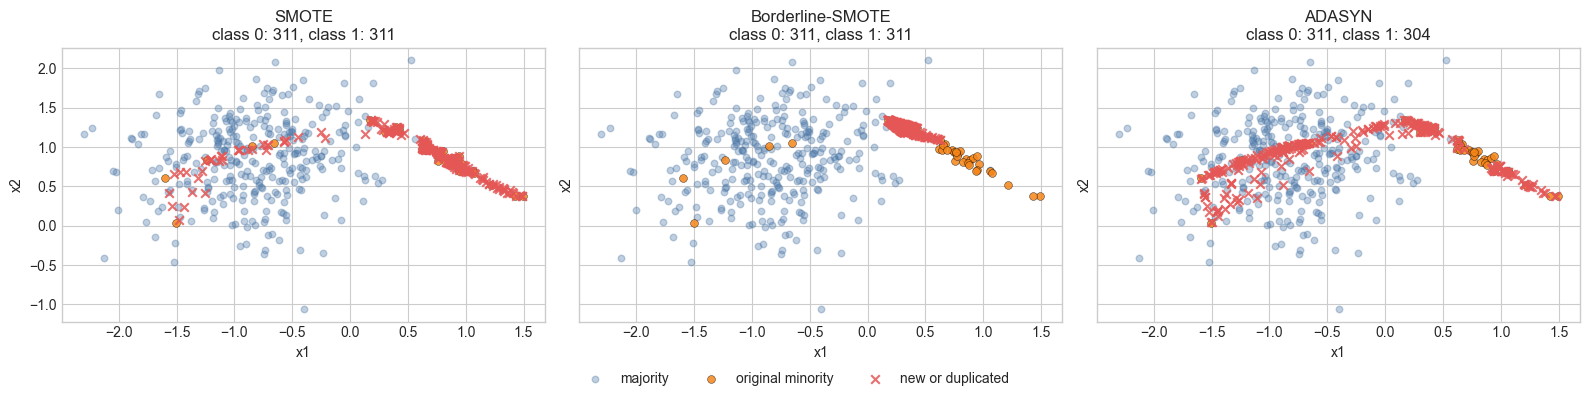

In [7]:
#| echo: false
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
for ax, (name, sampler) in zip(axes.ravel(), toy_samplers2.items()):
    X_resampled, y_resampled, original_mask = apply_sampler_for_plot(sampler, X_2d, y_2d)
    plot_resampled_dataset(ax, name, X_resampled, y_resampled, original_mask)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

- *SMOTE* fills segments between nearby minority points.
    - This smooths sparse minority regions, but assumes that interpolation produces valid records.
- *Borderline-SMOTE* tries to synthesize near the frontier between classes.
    - It is useful when boundary recall matters, but it can be sensitive to overlap and label noise.
- *ADASYN* places more synthetic examples in locally difficult regions.
    - Compared with SMOTE, it often concentrates more strongly near areas where the majority class surrounds the minority class.

# 14. Baseline pipeline

In [8]:
numeric_features = X.columns.tolist()
preprocessor = ColumnTransformer(
    transformers=[("num", StandardScaler(), numeric_features)],
    remainder="drop",
)
baseline_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]
)
baseline_pipeline


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains s

# 15. Candidate pipelines

We compare seven strategies (When we add a sampler, we switch to `imblearn.pipeline.Pipeline`):

1. No imbalance treatment (baseline pipeline).
2. `class_weight="balanced"`.
3. Random undersampling.
4. Random oversampling.
5. SMOTE.
6. ADASYN.
7. Borderline-SMOTE.

All samplers are placed after preprocessing and before the classifier, so they are fitted only on the current training fold.

```python
pipelines = {
    "No treatment": Pipeline(
        [("preprocessing", preprocessor), ("classifier", logistic_regression())]
    ),
    "Class weight": Pipeline(
        [("preprocessing", preprocessor), ("classifier", logistic_regression(class_weight="balanced"))]
    ),
    "Random undersampling": ImbPipeline(
        [("preprocessing", preprocessor), ("sampler", RandomUnderSampler(random_state=RANDOM_STATE)), ("classifier", logistic_regression())]
    ), # ...
}
```


In [9]:
#| echo: false
#| output: false
# Compare ordinary sklearn pipelines with imblearn pipelines that can contain samplers.
def logistic_regression(class_weight=None):
    return LogisticRegression(
        max_iter=2000,
        class_weight=class_weight,
        random_state=RANDOM_STATE,
    )


pipelines = {
    "No treatment": Pipeline(
        [("preprocessing", preprocessor), ("classifier", logistic_regression())]
    ),
    "Class weight": Pipeline(
        [
            ("preprocessing", preprocessor),
            ("classifier", logistic_regression(class_weight="balanced")),
        ]
    ),
    "Random undersampling": ImbPipeline(
        [
            ("preprocessing", preprocessor),
            ("sampler", RandomUnderSampler(random_state=RANDOM_STATE)),
            ("classifier", logistic_regression()),
        ]
    ),
    "Random oversampling": ImbPipeline(
        [
            ("preprocessing", preprocessor),
            ("sampler", RandomOverSampler(random_state=RANDOM_STATE)),
            ("classifier", logistic_regression()),
        ]
    ),
    "SMOTE": ImbPipeline(
        [
            ("preprocessing", preprocessor),
            ("sampler", SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
            ("classifier", logistic_regression()),
        ]
    ),
    "ADASYN": ImbPipeline(
        [
            ("preprocessing", preprocessor),
            ("sampler", ADASYN(random_state=RANDOM_STATE, n_neighbors=5)),
            ("classifier", logistic_regression()),
        ]
    ),
    "Borderline-SMOTE": ImbPipeline(
        [
            ("preprocessing", preprocessor),
            ("sampler", BorderlineSMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
            ("classifier", logistic_regression()),
        ]
    ),
}

list(pipelines)


['No treatment',
 'Class weight',
 'Random undersampling',
 'Random oversampling',
 'SMOTE',
 'ADASYN',
 'Borderline-SMOTE']

# 16. Stratified cross-validation (F1 score)

In [10]:
#| echo: false
# Fit a fresh pipeline in each fold so preprocessing and sampling never see validation rows.
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tn / (tn + fp) if (tn + fp) else np.nan


def evaluate_pipeline(name, pipeline, X, y, cv, threshold=0.5):
    fold_rows = []
    out_of_fold_scores = pd.Series(index=y.index, dtype=float)

    for fold, (train_idx, valid_idx) in enumerate(cv.split(X, y), start=1):
        model = clone(pipeline)
        X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
        y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

        model.fit(X_train, y_train)
        y_score = model.predict_proba(X_valid)[:, 1]
        y_pred = (y_score >= threshold).astype(int)
        out_of_fold_scores.iloc[valid_idx] = y_score

        fold_rows.append(
            {
                "method": name,
                "fold": fold,
                "accuracy": accuracy_score(y_valid, y_pred),
                "precision": precision_score(y_valid, y_pred, zero_division=0),
                "recall": recall_score(y_valid, y_pred, zero_division=0),
                "specificity": specificity_score(y_valid, y_pred),
                "f1": f1_score(y_valid, y_pred, zero_division=0),
            }
        )

    return pd.DataFrame(fold_rows), out_of_fold_scores


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fold_results = []
oof_scores = {}

for name, pipeline in pipelines.items():
    fold_df, scores = evaluate_pipeline(name, pipeline, X, y, cv)
    fold_results.append(fold_df)
    oof_scores[name] = scores

fold_results = pd.concat(fold_results, ignore_index=True)
fold_results.pivot(index="fold", columns="method", values="f1").round(3)


method,ADASYN,Borderline-SMOTE,Class weight,No treatment,Random oversampling,Random undersampling,SMOTE
fold,,,,,,,
1,0.258,0.287,0.247,0.080,0.245,0.257,0.253
2,0.272,0.296,0.259,0.135,0.259,0.249,0.268
3,0.285,0.295,0.280,0.028,0.281,0.275,0.285
4,0.278,0.307,0.285,0.107,0.280,0.266,0.290
5,0.305,0.330,0.302,0.104,0.303,0.292,0.308


# 17. Comparison table

The table reports mean cross-validation performance and fold-to-fold variability.

> - **Precision**: among predicted positives, how many were actually positive?
> - **Recall** or sensitivity: among actual positives, how many did we find?
> - **Specificity**: among actual negatives, how many did we correctly reject?
> - **F1 score**: harmonic mean of precision and recall.


In [11]:
#| echo: false
# Average fold-level metrics to compare strategies at the default 0.5 threshold.
summary = (
    fold_results.groupby("method")
    .agg(
        Accuracy=("accuracy", "mean"),
        Precision=("precision", "mean"),
        Recall=("recall", "mean"),
        Specificity=("specificity", "mean"),
        F1=("f1", "mean"),
        F1_std=("f1", "std"),
    )
    .sort_values("F1", ascending=False)
)

summary.round(3)


,Accuracy,Precision,Recall,Specificity,F1,F1_std
method,,,,,,
Borderline-SMOTE,0.773,0.192,0.719,0.777,0.303,0.017
SMOTE,0.734,0.172,0.754,0.733,0.281,0.021
ADASYN,0.732,0.172,0.757,0.730,0.279,0.017
Class weight,0.725,0.168,0.757,0.723,0.275,0.022
Random oversampling,0.726,0.167,0.751,0.724,0.274,0.022
Random undersampling,0.714,0.163,0.760,0.711,0.268,0.017
No treatment,0.932,0.552,0.050,0.997,0.091,0.040


# 18. Confusion matrices

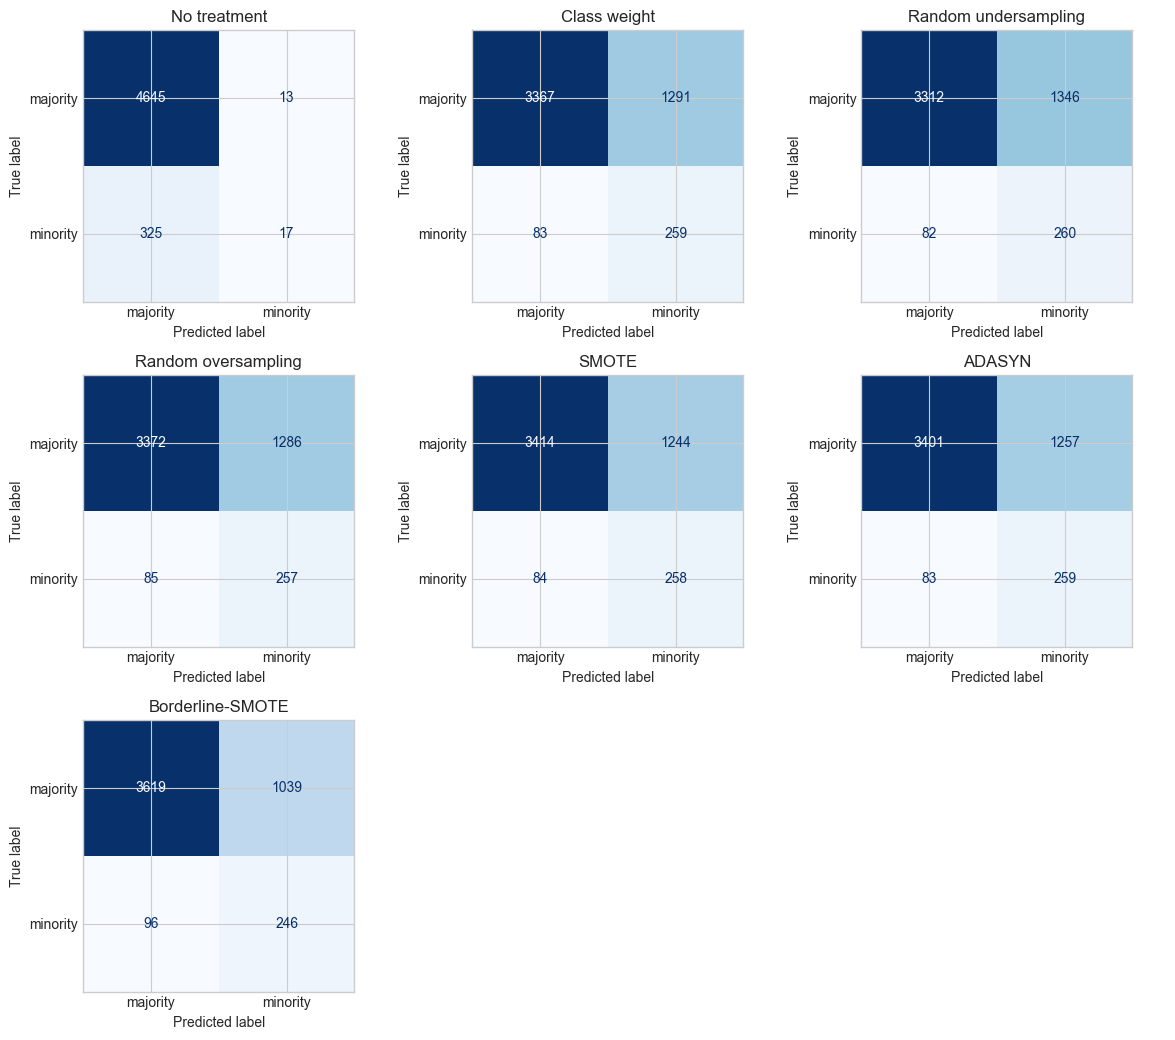

In [12]:
#| echo: false
# Convert out-of-fold probabilities into labels before drawing confusion matrices.
n_methods = len(oof_scores)
n_cols = 3
n_rows = int(np.ceil(n_methods / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 3.5 * n_rows))
axes = np.asarray(axes).ravel()

for ax in axes[n_methods:]:
    ax.axis("off")

for ax, (name, scores) in zip(axes, oof_scores.items()):
    y_pred = (scores >= 0.5).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y,
        y_pred,
        labels=[0, 1],
        display_labels=["majority", "minority"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


# 19. Precision-recall curves

:::: {.columns}
::: {.column width="80%"}

Precision ($\frac{TP}{TP + FP}$; high $\rightarrow$ few false alarms) and Recall ($\frac{TP}{TP + FN}$; high recall $\rightarrow$ few missed positives).

- *High recall but low precision*: return many positive results, but most of its predicted labels are incorrect.
- *High precision but low recall*: return few positive results, but most of its predicted labels are correct.

A model produces a positive-class probability $p$ and predicts positive when $p \ge thr$.

- The threshold $thr$ decides which scores become positive predictions


Lowering $thr$ changes the confusion matrix

- **Precision**

    - If $thr$ was too high, the new results may all be TP, which will increase precision.
    - If $thr$ was about right or low, further lowering it will introduce FP, decreasing precision.

- **Recall**

    - Lowering $thr$ labels more cases as positive, this can turn some FN into TP, increasing recall.

:::
::: {.column width="20%"}

![](img/PrecisionrecallDogExample.svg.png)

:::
::::

# Precision-recall curves

A precision-recall curve shows every precision/recall pair produced as we *vary the classification threshold* for binary classification.

- *Lower $thr$* predict more positives: *recall usually rises* and *precision often falls*.
- *Higher $thr$* predict fewer positives: *precision may rise* and *recall often falls*.
- Curves closer to the upper-right corner are better because they keep high precision while recovering many positives.

Average precision ($AP=\sum_n (R_n - R_{n-1}) P_n$) summarizes the curve as the weighted mean of precisions achieved at each threshold.

- $P_n$ and $R_n$ are the precision and recall at the nth threshold.
- The horizontal baseline is the positive-class rate: a model below this line is worse than ranking cases at random.

<div></div>

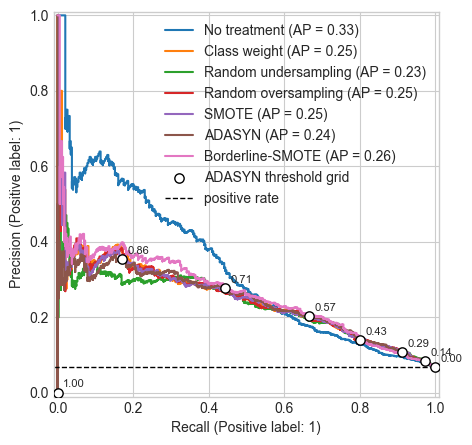

In [13]:
#| echo: false
# Plot precision-recall curves from validation-only scores for each method.
selected_method = "ADASYN"
threshold_grid = np.linspace(0.00, 1.00, 8)

fig, ax = plt.subplots(figsize=(8, 5))

for name, scores in oof_scores.items():
    PrecisionRecallDisplay.from_predictions(y, scores, name=name, ax=ax)

# Highlight the same ADASYN thresholds inspected in the next section.
threshold_points = []
selected_scores = oof_scores[selected_method]
for threshold in threshold_grid:
    y_pred = (selected_scores >= threshold).astype(int)
    threshold_points.append(
        {
            "threshold": threshold,
            "precision": precision_score(y, y_pred, zero_division=0),
            "recall": recall_score(y, y_pred, zero_division=0),
        }
    )

threshold_points = pd.DataFrame(threshold_points)
ax.scatter(
    threshold_points["recall"],
    threshold_points["precision"],
    color="white",
    edgecolor="black",
    linewidth=1,
    s=45,
    zorder=5,
    label=f"{selected_method} threshold grid",
)
for _, row in threshold_points.iterrows():
    ax.annotate(
        f"{row['threshold']:.2f}",
        (row["recall"], row["precision"]),
        textcoords="offset points",
        xytext=(4, 4),
        fontsize=8,
    )

positive_rate = y.mean()
ax.axhline(positive_rate, color="black", linestyle="--", linewidth=1, label="positive rate")
ax.legend(loc="best")
plt.show()


# 20. Threshold adjustment



The right threshold depends on the operational cost of each error type. It is not a property of the model alone.

- In a high-cost false-negative scenario, such as fraud detection or medical screening, we may prefer a lower threshold.

- Threshold tuning should be evaluated with data and business constraints that matches the real decision problem.

- `predict` usually applies a threshold of `0.5`.


In [14]:
#| echo: false
#| output: false
# Recompute metrics over a grid of decision thresholds for one selected method.
def metrics_at_thresholds(y_true, y_score, thresholds):
    rows = []
    for threshold in thresholds:
        y_pred = (y_score >= threshold).astype(int)
        rows.append(
            {
                "threshold": threshold,
                "precision": precision_score(y_true, y_pred, zero_division=0),
                "recall": recall_score(y_true, y_pred, zero_division=0),
                "specificity": specificity_score(y_true, y_pred),
                "f1": f1_score(y_true, y_pred, zero_division=0),
            }
        )
    return pd.DataFrame(rows)


# Reuse the method and thresholds highlighted on the precision-recall curve.
threshold_results = metrics_at_thresholds(y, oof_scores[selected_method], threshold_grid)
threshold_results.round(3)


,threshold,precision,recall,specificity,f1
0,0.000,0.068,1.000,0.000,0.128
1,0.143,0.084,0.974,0.221,0.155
2,0.286,0.107,0.912,0.440,0.191
3,0.429,0.140,0.801,0.637,0.238
4,0.571,0.203,0.667,0.807,0.311
5,0.714,0.277,0.444,0.915,0.341
6,0.857,0.354,0.170,0.977,0.229
7,1.000,0.000,0.000,1.000,0.000


Increasing $thr$ asks for more confidence before predicting the positive class, so recall tends to fall and precision may rise.

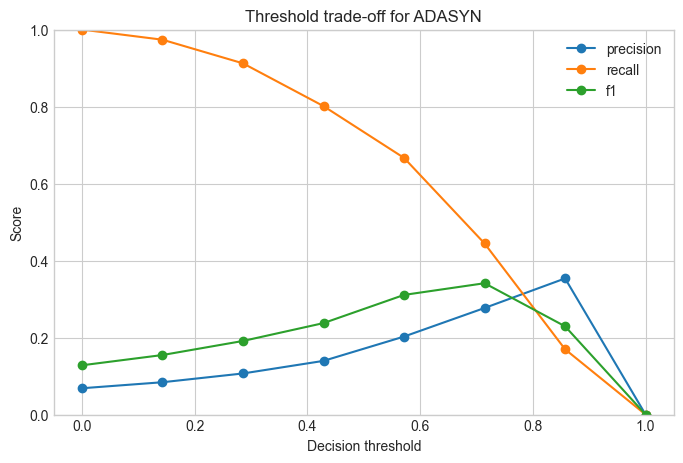

In [15]:
#| echo: false
# Plot the metric trade-off created by moving the classification threshold.
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(threshold_results["threshold"], threshold_results["precision"], marker="o", label="precision")
ax.plot(threshold_results["threshold"], threshold_results["recall"], marker="o", label="recall")
ax.plot(threshold_results["threshold"], threshold_results["f1"], marker="o", label="f1")
ax.set_title(f"Threshold trade-off for {selected_method}")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend()
plt.show()


# 21. Choose a threshold for high-cost false negatives

Suppose a false negative costs 10 times as much as a false positive.

- A false positive creates an unnecessary follow-up, while a false negative misses a truly high-risk case.
- With this cost ratio, the best threshold may accept more false positives if doing so prevents enough false negatives.

For each method and threshold, we compute the confusion matrix and then calculate:

- $total\ cost = FP \times cost(FP) + FN \times cost(FN)$

With $cost(FP)=1$ and $cost(FN)=10$, this becomes:

- $total\ cost = FP + 10 \times FN$
- If a threshold produces 961 false positives and 101 false negatives, then: $total\ cost = 961 + 10 \times 101 = 1971$


In [16]:
#| echo: false
# Search thresholds with a simple cost function where false negatives are expensive.
def cost_at_threshold(y_true, y_score, threshold, false_positive_cost=1, false_negative_cost=10):
    y_pred = (y_score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    total_cost = fp * false_positive_cost + fn * false_negative_cost
    return {
        "threshold": threshold,
        "false_positives": fp,
        "false_negatives": fn,
        "total_cost": total_cost,
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }


cost_rows = []
for method, scores in oof_scores.items():
    for threshold in np.linspace(0.05, 0.95, 91):
        row = cost_at_threshold(y, scores, threshold)
        row["method"] = method
        cost_rows.append(row)

cost_results = pd.DataFrame(cost_rows)
best_by_method = cost_results.loc[cost_results.groupby("method")["total_cost"].idxmin()]
best_by_method.sort_values("total_cost").round(3)


,threshold,false_positives,false_negatives,total_cost,precision,recall,f1,method
593,0.52,961,101,1971,0.200,0.705,0.312,Borderline-SMOTE
505,0.55,993,101,2003,0.195,0.705,0.306,ADASYN
328,0.60,795,123,2025,0.216,0.640,0.323,Random oversampling
231,0.54,1126,90,2026,0.183,0.737,0.293,Random undersampling
140,0.54,1068,96,2028,0.187,0.719,0.297,Class weight
415,0.56,959,107,2029,0.197,0.687,0.306,SMOTE
6,0.11,694,143,2124,0.223,0.582,0.322,No treatment


# 22. Leakage demonstration

- The **wrong** structure applies SMOTE before cross-validation. 
    - The validation folds are no longer clean because the synthetic data was produced using information from the full dataset.
- The **right** structure places SMOTE inside an `imblearn` pipeline, so SMOTE is fitted only on each training fold.


In [17]:
#| echo: false
# Contrast an intentionally leaky workflow with the leakage-safe pipeline workflow.
# Wrong pattern for teaching purposes only: do not use this as an evaluation design.
X_scaled = preprocessor.fit_transform(X)
X_leaky, y_leaky = SMOTE(random_state=RANDOM_STATE).fit_resample(X_scaled, y)

leaky_pipeline = Pipeline(
    [("classifier", logistic_regression())]
)

leaky_fold_results, _ = evaluate_pipeline(
    "Leaky SMOTE before CV",
    leaky_pipeline,
    pd.DataFrame(X_leaky),
    pd.Series(y_leaky),
    cv,
)

right_fold_results, _ = evaluate_pipeline("SMOTE inside CV", pipelines["SMOTE"], X, y, cv)

pd.concat([leaky_fold_results, right_fold_results])\
    .groupby("method")[["accuracy", "precision", "recall", "specificity", "f1"]]\
    .mean()\
    .round(3)


,accuracy,precision,recall,specificity,f1
method,,,,,
Leaky SMOTE before CV,0.758,0.746,0.782,0.733,0.763
SMOTE inside CV,0.734,0.172,0.754,0.733,0.281


# 23. Guided exercises: sklearn versus imblearn pipelines

Use these exercises to practice the difference between ordinary `sklearn` pipelines and `imblearn`.

## Exercise 1: create an imbalanced dataset with different feature ranges

In [18]:
X_exercise = X.copy()
y_exercise = y.copy()

scale_factors = np.array([1, 10, 100, 1000, 0.1, 0.01, 1, 10, 100, 1000, 0.1, 0.01])
X_exercise = X_exercise * scale_factors

X_train, X_valid, y_train, y_valid = train_test_split(
    X_exercise,
    y_exercise,
    test_size=0.30,
    stratify=y_exercise,
    random_state=RANDOM_STATE,
)

pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index(),
    "valid": y_valid.value_counts(normalize=True).sort_index(),
})

,train,valid
high_risk,,
0,0.931714,0.931333
1,0.068286,0.068667


**Question:** why is `stratify=y_exercise` important for an imbalanced classification problem?

## Exercise 2: implement a scikit-learn pipeline

Build a standard `sklearn.pipeline.Pipeline` with standardization and logistic regression (check the initial cards of the notebook).

1. Create a `ColumnTransformer` that standardizes all numeric features.
2. Create a `Pipeline` with preprocessing and logistic regression.
3. Fit the pipeline on the training data.
4. Evaluate accuracy and F1 score on the validation data.

**Questions:** is accuracy high? Is F1 also high? What does this tell you about imbalanced data?

In [19]:
# your code here

## Exercise 3: add SMOTE with an imblearn pipeline

Now add a sampler. Because SMOTE changes both `X` and `y`, use `imblearn.pipeline.Pipeline`.

1. Replace `Pipeline` with `ImbPipeline`.
2. Insert `SMOTE` between preprocessing and logistic regression.
3. Fit the pipeline on the same training data.
4. Evaluate accuracy and F1 score on the same validation data.
5. Compare the result with Exercise 2.

**Questions:** how did F1 change? Did accuracy move in the same direction? Why can the answer differ?

In [20]:
# your code here

## Exercise 4: apply SMOTE before preprocessing

1. Apply SMOTE directly to the unscaled training data.
2. Fit a normal `sklearn` pipeline with standardization and logistic regression on the resampled data.
3. Evaluate on the original, untouched validation data.
4. Compare this result with the pipeline where standardization happened before SMOTE.

**Questions:** did applying SMOTE before standardization change the result?

In [21]:
# your code here

# 24. Challenge

Dataset: [Credit Card Fraud Detection on Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud).

1. Define the cost of a false negative.
2. Select a primary metric.
3. Compare at least three imbalance strategies.
4. Tune the classification threshold.
5. Defend the final choice with evidence.

In [22]:
# your code here

# References